# Taller 2 — Notebook 03: Exploración de los datos limpios

**MINE-4101: Ciencia de Datos Aplicada · Predicción de abandono (churn) para FinAlpes**

**Integrantes:** Daniel Triviño · Nicolás Bedoya

---

## De qué va este notebook

Con los datos ya limpios (salida del `02`) miramos dos cosas:

1. **Cómo se reparte cada variable por sí sola**: la forma de su distribución, si está cargada hacia un lado, si
   tiene picos.
2. **Cómo se relaciona cada variable con el churn**: si los clientes que abandonan se diferencian de los que se
   quedan. Esto adelanta qué variables probablemente le sirvan al modelo.

Los faltantes siguen en los datos (se imputan en el pipeline del modelo); cada gráfico simplemente usa los valores
disponibles de su variable.

> Ejecutar **después** de `02_limpieza`.


In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')

RUTA_LIMPIO = '../data/processed/churn_limpio.parquet'
RUTA_FIGS = '../figs'
os.makedirs(RUTA_FIGS, exist_ok=True)

df = pd.read_parquet(RUTA_LIMPIO)
# credit_score y age vienen como enteros que admiten faltantes (Int64); para graficar y calcular estadísticos
# los pasamos a float. Sus valores siguen siendo enteros.
df[['credit_score', 'age']] = df[['credit_score', 'age']].astype(float)

OBJETIVO = 'churn'
tasa_global = df[OBJETIVO].mean() * 100
print(f'Filas: {len(df):,}  |  columnas: {df.shape[1]}  |  tasa de churn: {tasa_global:.2f}%')


Filas: 9,985  |  columnas: 11  |  tasa de churn: 20.38%


In [2]:
# Grupos para graficar, según cuántos valores distintos tiene cada variable (no según su tipo):
# con muchos valores conviene un histograma; con pocos, barras.
NUM_MUCHOS_VALORES = ['credit_score', 'age', 'balance', 'estimated_salary']
NUM_POCOS_VALORES = ['tenure', 'products_number']
CATEGORICAS = ['country', 'gender']
BINARIAS = ['credit_card', 'active_member']


## 1. Variables numéricas, una por una

Un resumen de cada variable numérica: la media y la mediana (si están muy separadas, la distribución está cargada a
un lado), la **asimetría** (0 es simétrica; positiva, cola larga hacia la derecha; negativa, hacia la izquierda), el %
de ceros y cuántos faltantes tiene.


In [3]:
numericas = NUM_MUCHOS_VALORES + NUM_POCOS_VALORES
resumen = df[numericas].describe().T[['mean', '50%', 'std', 'min', 'max']]
resumen.columns = ['media', 'mediana', 'desv_est', 'min', 'max']
resumen['asimetria'] = df[numericas].skew()
resumen['pct_ceros'] = (df[numericas] == 0).mean() * 100
resumen['faltantes'] = df[numericas].isna().sum()
resumen


,media,mediana,desv_est,min,max,asimetria,pct_ceros,faltantes
credit_score,650.60,652.00,96.57,350.00,850.00,-0.07,0.00,250
age,38.92,37.00,10.47,18.00,92.00,1.00,0.00,300
balance,"76,309.91","97,041.16","62,403.59",0.00,"250,898.09",-0.14,35.56,200
estimated_salary,"100,080.58","100,137.70","57,474.40",11.58,"199,992.48",0.00,0.00,350
tenure,5.01,5.00,2.89,0.00,15.00,0.01,4.14,0
products_number,1.53,1.00,0.58,1.00,4.00,0.75,0.00,0


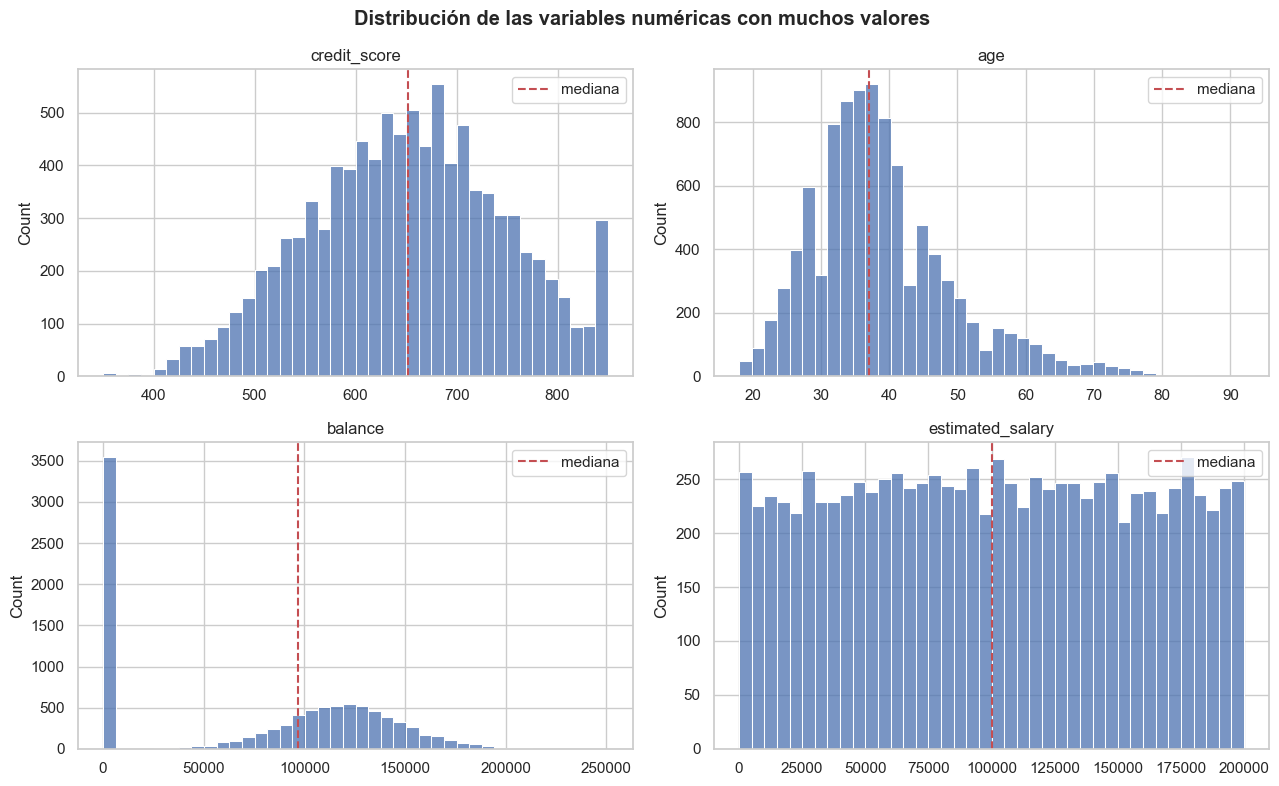

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), NUM_MUCHOS_VALORES):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color='#4C72B0')
    ax.axvline(df[col].median(), color='#C44E52', ls='--', lw=1.5, label='mediana')
    ax.set_title(col); ax.set_xlabel(''); ax.legend()
fig.suptitle('Distribución de las variables numéricas con muchos valores', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/03_hist_numericas.png', bbox_inches='tight'); plt.show()


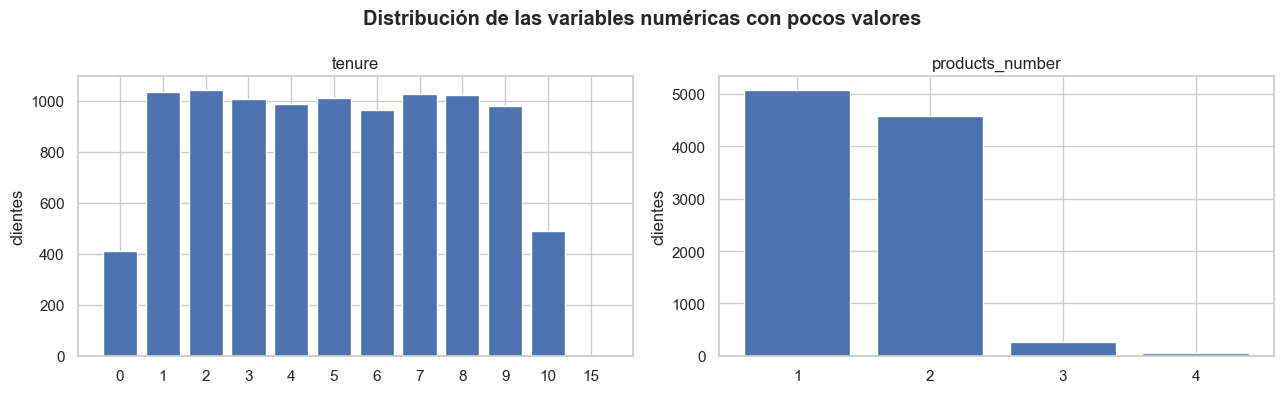

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, NUM_POCOS_VALORES):
    conteo = df[col].value_counts().sort_index()
    ax.bar(conteo.index.astype(str), conteo.values, color='#4C72B0')
    ax.set_title(col); ax.set_ylabel('clientes')
fig.suptitle('Distribución de las variables numéricas con pocos valores', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/03_barras_discretas.png', bbox_inches='tight'); plt.show()


**Qué vemos:** _(por completar)_

## 2. Variables categóricas y binarias, una por una

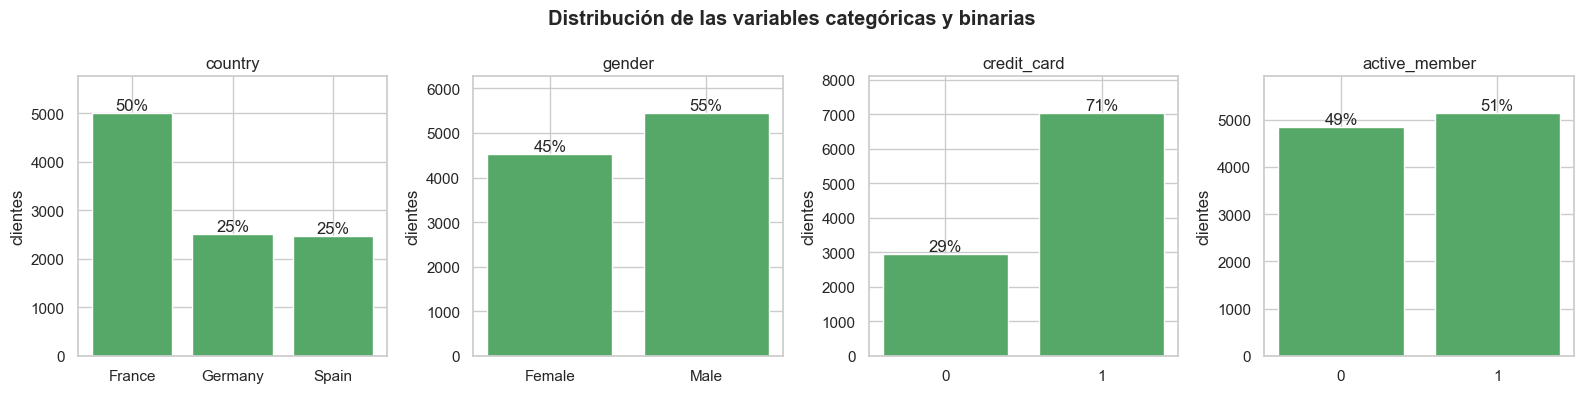

In [6]:
cols = CATEGORICAS + BINARIAS
fig, axes = plt.subplots(1, len(cols), figsize=(16, 4))
for ax, col in zip(axes, cols):
    conteo = df[col].value_counts().sort_index()
    pct = conteo / conteo.sum() * 100
    barras = ax.bar(conteo.index.astype(str), conteo.values, color='#55A868')
    for barra, p in zip(barras, pct):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), f'{p:.0f}%', ha='center', va='bottom')
    ax.set_ylim(0, conteo.max() * 1.15)
    ax.set_title(col); ax.set_ylabel('clientes')
fig.suptitle('Distribución de las variables categóricas y binarias', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/03_barras_categoricas.png', bbox_inches='tight'); plt.show()


**Qué vemos:** _(por completar)_

## 3. Cada variable frente al churn

### 3.1 Tasa de churn por grupo

Para cada variable con pocos valores calculamos qué % de los clientes de cada grupo abandona. En el gráfico, el
**alto de cada barra es el número de clientes del grupo**, y la parte roja, los que abandonan. Encima de cada barra
va la tasa de churn y el conteo exacto (abandonos de clientes). Así se ve a la vez qué tan grande es cada grupo y qué
proporción se va: una tasa muy alta en un grupo diminuto pesa mucho menos que una tasa moderada en un grupo grande.

Agregamos, solo para explorar, un grupo que no es una columna del dataset: **saldo en cero** (sí/no). En la sección 1
se ve que `balance` tiene muchísimos ceros, así que vale la pena mirar si esos clientes se comportan distinto.


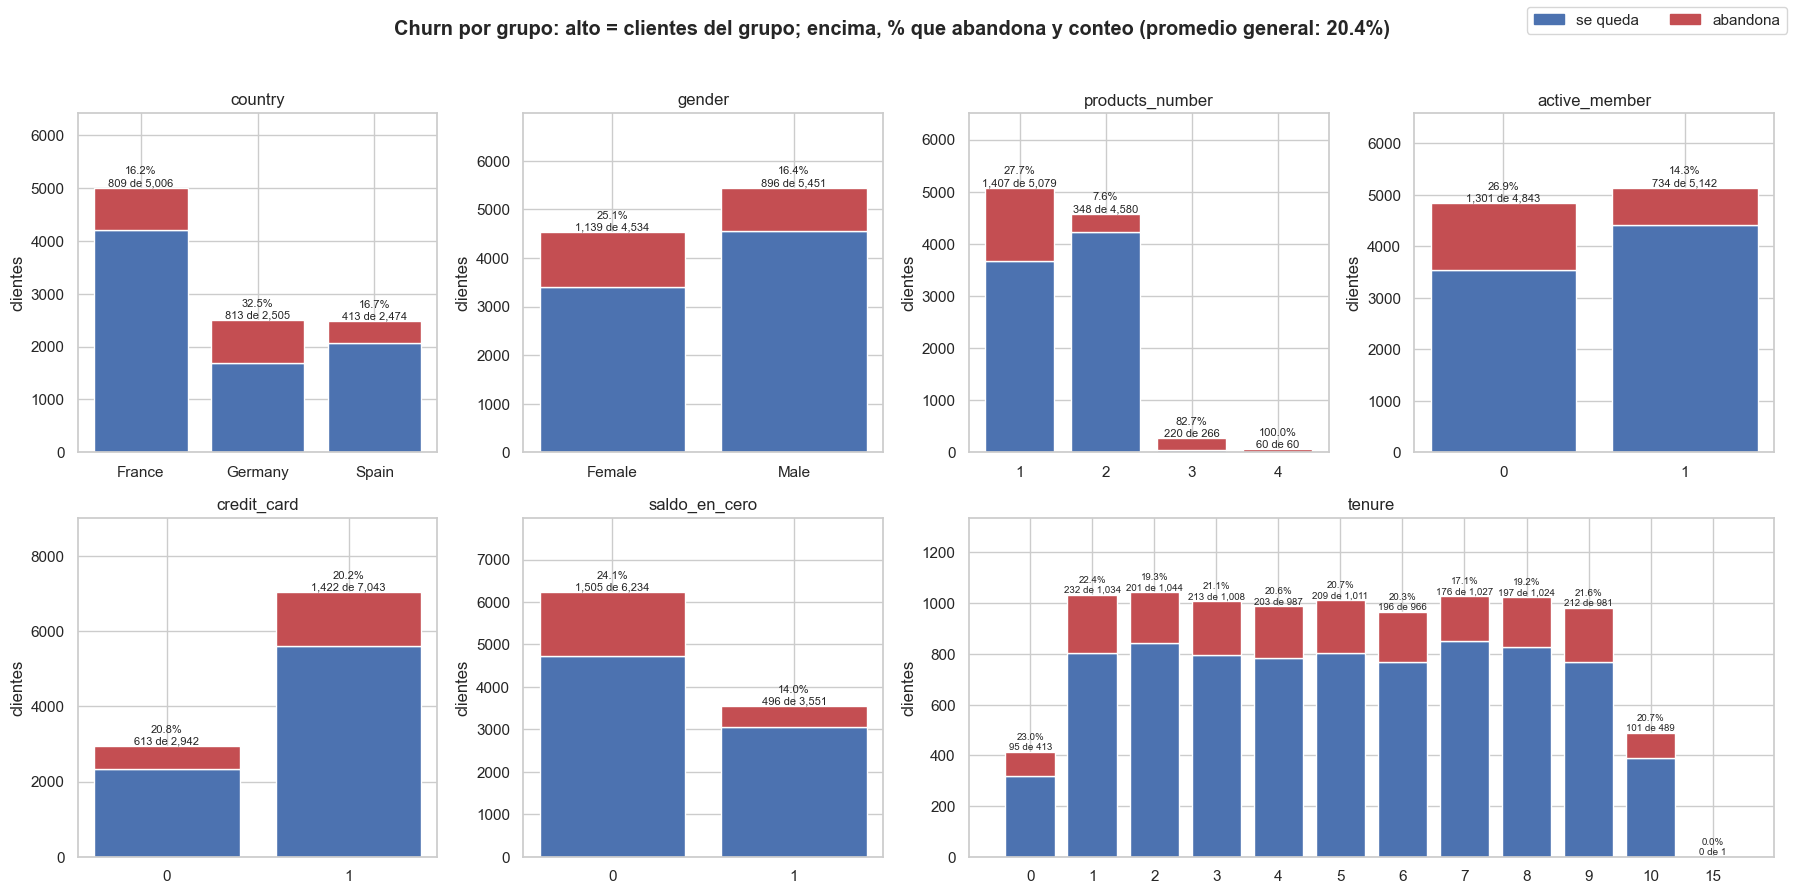

In [7]:
def tasa_churn(datos, col):
    '''Clientes, abandonos y tasa de churn (%) por cada valor de `col`.'''
    t = datos.groupby(col, observed=True)[OBJETIVO].agg(clientes='size', abandonos='sum', tasa='mean')
    t['tasa'] = t['tasa'] * 100
    return t

explorar = df.assign(saldo_en_cero=np.where(df['balance'].isna(), np.nan, (df['balance'] == 0).astype(float)))
GRUPOS = ['country', 'gender', 'products_number', 'active_member', 'credit_card', 'tenure', 'saldo_en_cero']
tasas = {col: tasa_churn(explorar, col) for col in GRUPOS}

def barras_churn(ax, t, titulo, fuente=8):
    '''Barras apiladas: alto = clientes del grupo, rojo = los que abandonan. Encima: tasa y conteo exacto.'''
    etiquetas = [str(int(i)) if isinstance(i, float) else str(i) for i in t.index]
    se_quedan = t['clientes'] - t['abandonos']
    ax.bar(etiquetas, se_quedan, color='#4C72B0')
    ax.bar(etiquetas, t['abandonos'], bottom=se_quedan, color='#C44E52')
    for x, (n, a, tasa) in enumerate(zip(t['clientes'], t['abandonos'], t['tasa'])):
        ax.text(x, n, f'{tasa:.1f}%\n{a:,} de {n:,}', ha='center', va='bottom', fontsize=fuente)
    ax.set_ylim(0, t['clientes'].max() * 1.28)
    ax.set_title(titulo); ax.set_ylabel('clientes')

fig = plt.figure(figsize=(18, 9))
rejilla = fig.add_gridspec(2, 4)
paneles = {'country': rejilla[0, 0], 'gender': rejilla[0, 1], 'products_number': rejilla[0, 2],
           'active_member': rejilla[0, 3], 'credit_card': rejilla[1, 0], 'saldo_en_cero': rejilla[1, 1],
           'tenure': rejilla[1, 2:]}
for col, panel in paneles.items():
    barras_churn(fig.add_subplot(panel), tasas[col], col, fuente=7 if col == 'tenure' else 8)

leyenda = [plt.Rectangle((0, 0), 1, 1, color='#4C72B0'), plt.Rectangle((0, 0), 1, 1, color='#C44E52')]
fig.legend(leyenda, ['se queda', 'abandona'], loc='upper right', ncol=2)
fig.suptitle(f'Churn por grupo: alto = clientes del grupo; encima, % que abandona y conteo '
             f'(promedio general: {tasa_global:.1f}%)', fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(f'{RUTA_FIGS}/03_tasa_churn_por_grupo.png', bbox_inches='tight'); plt.show()


In [8]:
with pd.option_context('display.float_format', lambda x: f'{x:,.1f}'):
    for col, t in tasas.items():
        print(f'--- {col} ---')
        display(t)


--- country ---


,clientes,abandonos,tasa
country,,,
France,5006,809,16.2
Germany,2505,813,32.5
Spain,2474,413,16.7


--- gender ---


,clientes,abandonos,tasa
gender,,,
Female,4534,1139,25.1
Male,5451,896,16.4


--- products_number ---


...

,clientes,abandonos,tasa
credit_card,,,
0,2942,613,20.8
1,7043,1422,20.2


--- tenure ---


,clientes,abandonos,tasa
tenure,,,
0,413,95,23.0
1,1034,232,22.4
2,1044,201,19.3
3,1008,213,21.1
4,987,203,20.6
5,1011,209,20.7
6,966,196,20.3
7,1027,176,17.1
8,1024,197,19.2


--- saldo_en_cero ---


,clientes,abandonos,tasa
saldo_en_cero,,,
0.0,6234,1505,24.1
1.0,3551,496,14.0


**¿Qué variable separa más el churn?** Para cada variable, la diferencia entre el grupo con la tasa de churn más
alta y el de la más baja, en puntos porcentuales. Solo cuentan los grupos con al menos `MIN_CLIENTES` clientes, para
que un grupo diminuto no infle la diferencia.


In [9]:
MIN_CLIENTES = 50

filas = []
for col, t in tasas.items():
    t = t[t['clientes'] >= MIN_CLIENTES]
    filas.append({'variable': col,
                  'grupo_mayor_tasa': t['tasa'].idxmax(), 'mayor_tasa': t['tasa'].max(),
                  'grupo_menor_tasa': t['tasa'].idxmin(), 'menor_tasa': t['tasa'].min(),
                  'diferencia_pp': t['tasa'].max() - t['tasa'].min()})
diferencias = pd.DataFrame(filas).set_index('variable').sort_values('diferencia_pp', ascending=False)
with pd.option_context('display.float_format', lambda x: f'{x:,.1f}'):
    display(diferencias)


,grupo_mayor_tasa,mayor_tasa,grupo_menor_tasa,menor_tasa,diferencia_pp
variable,,,,,
products_number,4,100.0,2,7.6,92.4
country,Germany,32.5,France,16.2,16.3
active_member,0,26.9,1,14.3,12.6
saldo_en_cero,0.0,24.1,1.0,14.0,10.2
gender,Female,25.1,Male,16.4,8.7
tenure,0,23.0,7,17.1,5.9
credit_card,0,20.8,1,20.2,0.6


**Qué vemos:** _(por completar)_

### 3.2 Variables numéricas: los que se van frente a los que se quedan

Agrupamos cada variable numérica en **tramos** (rangos de valores) y usamos el mismo gráfico de 3.1: el alto de cada
barra es el número de clientes del tramo, la parte roja son los que abandonan, y encima va la tasa de churn y el conteo
exacto. Así se ve en qué valores se concentran los clientes y en cuáles se van más. Los tramos están en `TRAMOS` y se
pueden ajustar; `balance` tiene un tramo propio para el saldo en 0 por la cantidad de ceros. Los faltantes de cada
variable quedan fuera de su gráfico.

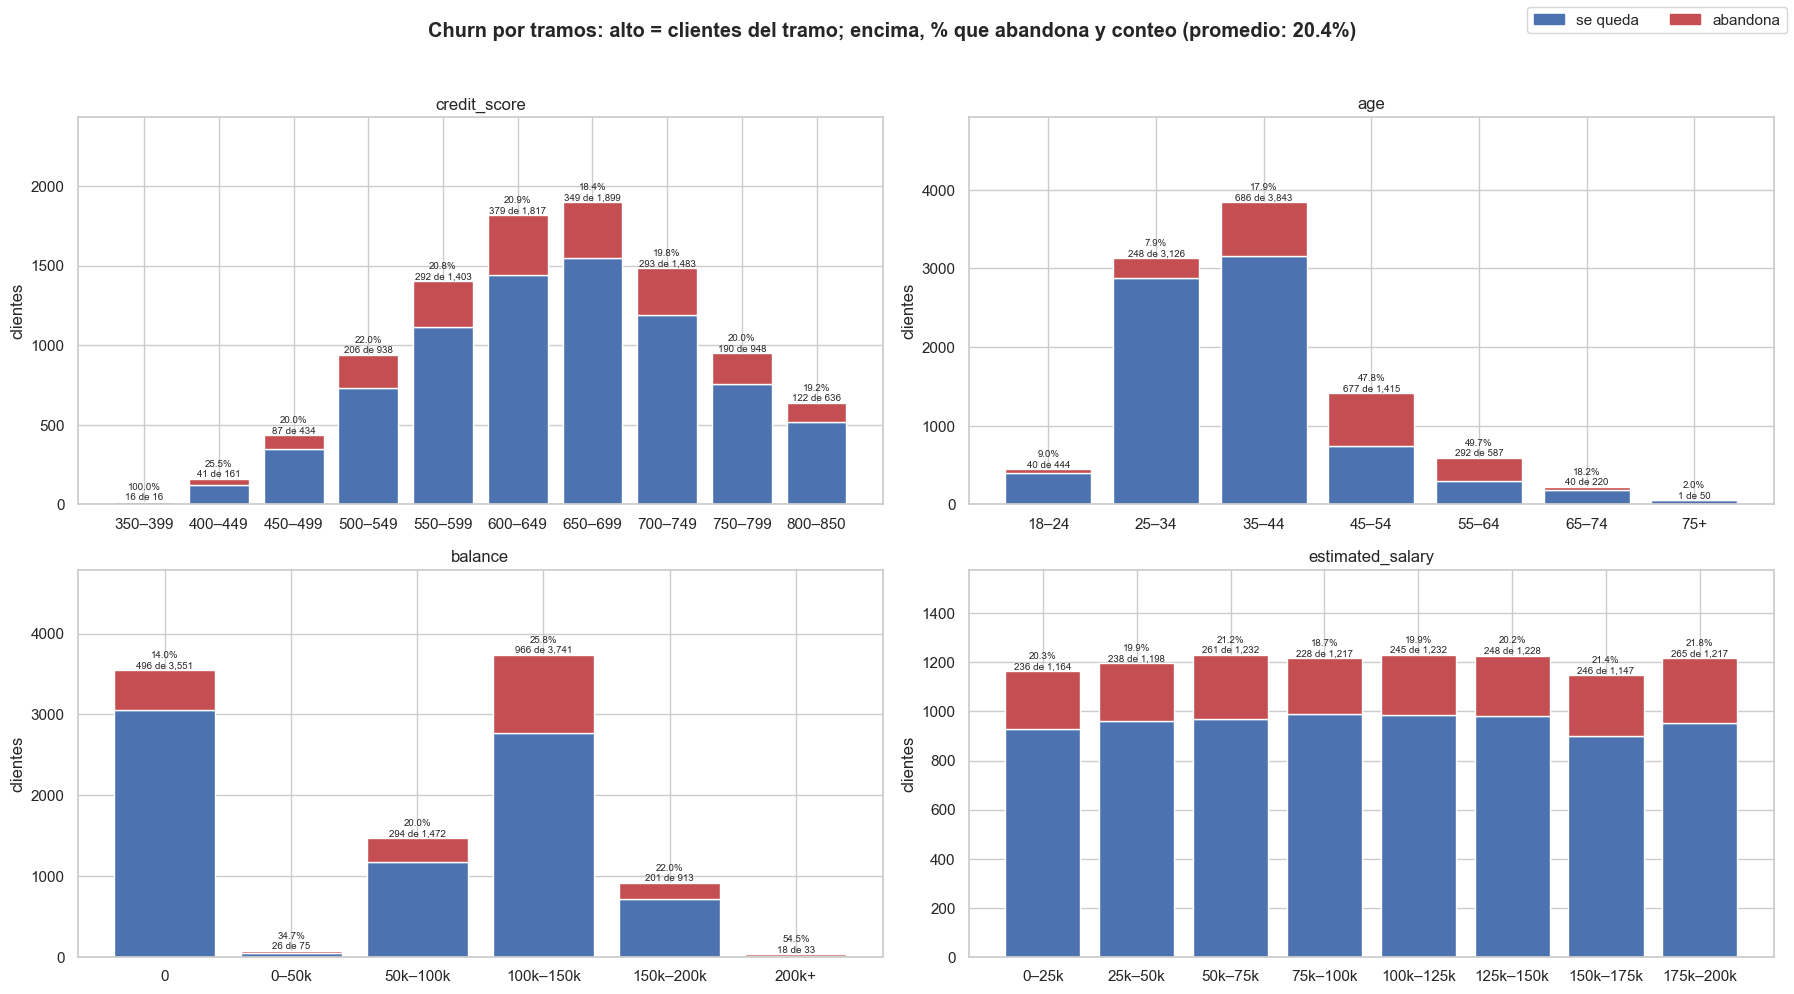

,mediana_se_queda,mediana_abandona
credit_score,654.00,646.00
age,36.00,45.00
balance,"91,883.74","109,153.96"
estimated_salary,"99,657.80","101,954.78"
tenure,5.00,5.00
products_number,2.00,1.00


In [10]:
# Tramos de cada variable: (bordes, etiquetas). Cada tramo incluye su borde inferior y excluye el superior.
TRAMOS = {
    'credit_score': ([350, 400, 450, 500, 550, 600, 650, 700, 750, 800, 851],
                     ['350–399', '400–449', '450–499', '500–549', '550–599', '600–649', '650–699',
                      '700–749', '750–799', '800–850']),
    'age': ([18, 25, 35, 45, 55, 65, 75, 101],
            ['18–24', '25–34', '35–44', '45–54', '55–64', '65–74', '75+']),
    'balance': ([0, 0.01, 50_000, 100_000, 150_000, 200_000, 260_000],
                ['0', '0–50k', '50k–100k', '100k–150k', '150k–200k', '200k+']),
    'estimated_salary': ([0, 25_000, 50_000, 75_000, 100_000, 125_000, 150_000, 175_000, 200_001],
                         ['0–25k', '25k–50k', '50k–75k', '75k–100k', '100k–125k', '125k–150k',
                          '150k–175k', '175k–200k']),
}

tasas_tramos = {}
for col, (bordes, etiquetas) in TRAMOS.items():
    tramo = pd.cut(df[col], bins=bordes, labels=etiquetas, right=False)
    assert tramo.notna().sum() == df[col].notna().sum(), f'Hay valores de {col} fuera de los tramos'
    tasas_tramos[col] = tasa_churn(df.assign(tramo=tramo), 'tramo')

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for ax, col in zip(axes.ravel(), NUM_MUCHOS_VALORES):
    barras_churn(ax, tasas_tramos[col], col, fuente=7)
    ax.set_xlabel('')
fig.legend(leyenda, ['se queda', 'abandona'], loc='upper right', ncol=2)
fig.suptitle(f'Churn por tramos: alto = clientes del tramo; encima, % que abandona y conteo '
             f'(promedio: {tasa_global:.1f}%)', fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(f'{RUTA_FIGS}/03_numericas_por_churn.png', bbox_inches='tight'); plt.show()

medianas = df.groupby(OBJETIVO)[NUM_MUCHOS_VALORES + NUM_POCOS_VALORES].median().T
medianas.columns = ['mediana_se_queda', 'mediana_abandona']
medianas


**Qué vemos:** _(por completar)_

## 4. Correlación entre variables

Correlación de Spearman entre las variables numéricas y binarias, incluido el churn. Usamos Spearman en lugar de
Pearson porque mide relaciones que van en una misma dirección aunque no sean líneas rectas, y es menos sensible a
variables con forma rara (como el saldo, con tantos ceros). Va de −1 a 1; cerca de 0 significa que no hay relación.


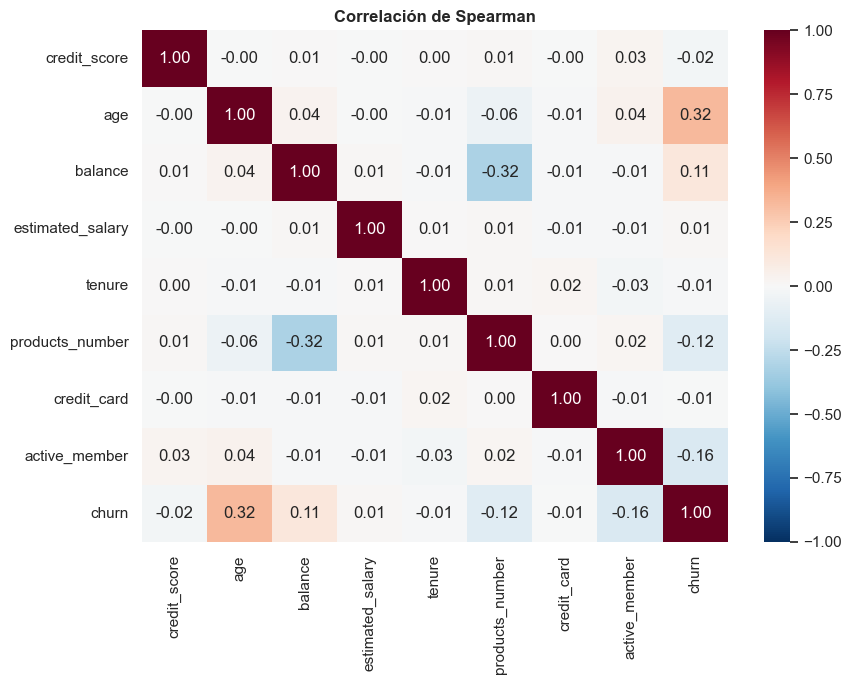

,correlacion_con_churn
age,0.32
active_member,-0.16
products_number,-0.12
balance,0.11
credit_score,-0.02
tenure,-0.01
estimated_salary,0.01
credit_card,-0.01


In [11]:
cols_corr = NUM_MUCHOS_VALORES + NUM_POCOS_VALORES + BINARIAS + [OBJETIVO]
corr = df[cols_corr].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlación de Spearman', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/03_correlacion.png', bbox_inches='tight'); plt.show()

corr[OBJETIVO].drop(OBJETIVO).sort_values(key=abs, ascending=False).to_frame('correlacion_con_churn')


**Qué vemos:** _(por completar)_